In [2]:
import pandas as pd
import os

### Loading the data

In [3]:


base_path = "./data/LA/"
train_protocol_path = os.path.join(base_path, "ASVspoof2019_LA_cm_protocols", "ASVspoof2019.LA.cm.train.trn.txt")
train_audio_folder = os.path.join(base_path, "ASVspoof2019_LA_train", "flac")

# collumns based on the README of the original dataset
columns = ["speaker_id", "audio_file_name", "ignored", "system_id", "label"]

df_train = pd.read_csv(train_protocol_path, sep=" ", header=None, names=columns)

df_train = df_train.drop(columns=["ignored"])


df_train['file_path'] = df_train['audio_file_name'].apply(lambda x: os.path.join(train_audio_folder, x + ".flac"))

df_train.sample(10)

,speaker_id,audio_file_name,system_id,label,file_path
9927,LA_0097,LA_T_7089443,A02,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
24624,LA_0095,LA_T_1351241,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
13369,LA_0095,LA_T_7843157,A03,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
8993,LA_0092,LA_T_8816950,A02,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
9729,LA_0096,LA_T_6573413,A02,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
24545,LA_0094,LA_T_6663175,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
17610,LA_0098,LA_T_1810211,A04,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
22501,LA_0083,LA_T_8584584,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
22283,LA_0082,LA_T_7574942,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
8292,LA_0089,LA_T_2952924,A02,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/A...


### Data cleaning

In [4]:

df_train['label'] = df_train['label'].map({'bonafide': 0, 'spoof': 1})

df_train = df_train.drop(columns=['audio_file_name'])

#sanity check
df_train['file_exists'] = df_train['file_path'].apply(os.path.exists)
print(f"Missing files: {len(df_train[df_train['file_exists'] == False])}")
df_train.sample(10)

Missing files: 0


,speaker_id,system_id,label,file_path,file_exists
8147,LA_0088,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
21348,LA_0097,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
18461,LA_0082,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
4143,LA_0087,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
14026,LA_0079,A04,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
8706,LA_0091,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
4802,LA_0090,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
8025,LA_0087,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
2447,LA_0097,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True
9043,LA_0093,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,True


In [5]:
df_train = df_train.drop(columns=['file_exists'])

In [6]:
df_train.sample(10)

,speaker_id,system_id,label,file_path
6384,LA_0079,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
16790,LA_0093,A04,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
9233,LA_0094,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
19781,LA_0089,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
8628,LA_0090,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
24508,LA_0094,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
20763,LA_0094,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
13794,LA_0098,A03,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
15510,LA_0087,A04,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
19109,LA_0086,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...


Checking if we have unbalanced data, which we do (we always do ffs)

In [7]:
df_train[df_train["label"] == 0].value_counts(dropna = False)

speaker_id  system_id  label  file_path                                                                                
LA_0079     -          0      /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1138215.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1271820.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1272637.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1276960.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1341447.flac    1
                                                                                                                          ..
LA_0098     -          0      /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_9387015.flac    1
     

In [8]:
df_train[df_train["label"] == 1].value_counts(dropna = False)

speaker_id  system_id  label  file_path                                                                                
LA_0079     A01        1      /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1004644.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1056709.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1195221.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1265032.flac    1
                              /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1287124.flac    1
                                                                                                                          ..
LA_0098     A06        1      /home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_train/flac/LA_T_9717580.flac    1
     

To solve imbalaced data i did some undersampling 22800 -> 7500 for the spoofed audios, not really necesary but i did it to train faster on my poor gpu
Later i ll give a weight of 3 to the bonafied audios since the ratio is now 1:3

In [9]:

df_real = df_train[df_train['label'] == 0]
df_fake = df_train[df_train['label'] == 1]


df_fake_sampled = df_fake.sample(n=7500, random_state=42)


df_train_balanced = pd.concat([df_real, df_fake_sampled])


df_train_balanced = df_train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)


print("New Class Distribution:")
print(df_train_balanced['label'].value_counts())

New Class Distribution:
label
1    7500
0    2580
Name: count, dtype: int64


In [10]:
df_train = df_train_balanced
print(df_train['label'].value_counts())
df_train.sample(10)

label
1    7500
0    2580
Name: count, dtype: int64


,speaker_id,system_id,label,file_path
3748,LA_0083,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
7473,LA_0088,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
9500,LA_0085,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
3028,LA_0087,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
9487,LA_0080,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
8204,LA_0098,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
2208,LA_0079,A03,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
375,LA_0084,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
9505,LA_0079,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
687,LA_0083,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...


In [11]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

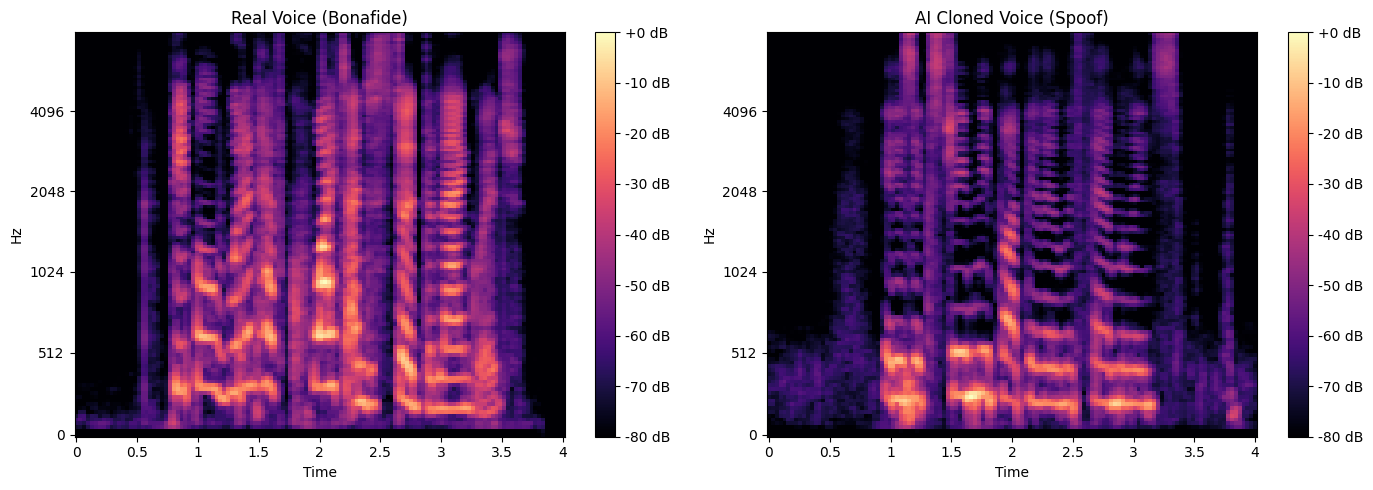

In [12]:
def generate_mel_spectrogram(file_path, target_seconds=4, sample_rate=16000):
    
    target_length = target_seconds * sample_rate
    
    
    y, sr = librosa.load(file_path, sr=sample_rate)
    
    
    y_fixed = librosa.util.fix_length(data=y, size=target_length)
    
    
    mel_spec = librosa.feature.melspectrogram(y=y_fixed, sr=sr, n_mels=128)
    
    
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    
    return mel_spec_db


sample_real_path = df_train[df_train['label'] == 0].iloc[0]['file_path']
sample_fake_path = df_train[df_train['label'] == 1].iloc[0]['file_path']


spec_real = generate_mel_spectrogram(sample_real_path)
spec_fake = generate_mel_spectrogram(sample_fake_path)


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(spec_real, sr=16000, x_axis='time', y_axis='mel', ax=ax[0])
ax[0].set_title('Real Voice (Bonafide)')
fig.colorbar(img1, ax=ax[0], format='%+2.0f dB')

img2 = librosa.display.specshow(spec_fake, sr=16000, x_axis='time', y_axis='mel', ax=ax[1])
ax[1].set_title('AI Cloned Voice (Spoof)')
fig.colorbar(img2, ax=ax[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

In [13]:
from tqdm import tqdm

In [22]:
df_train_img = df_train.copy()
df_train_img.sample(10)

,speaker_id,system_id,label,file_path
7049,LA_0095,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
5287,LA_0084,A04,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
8409,LA_0093,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
10032,LA_0089,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
2693,LA_0086,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
79,LA_0082,A03,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
72,LA_0096,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
4065,LA_0090,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
4917,LA_0089,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...
712,LA_0095,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...


In [23]:

output_base_dir = "data/dataset_img/train"

def compute_img_path(row):
    subfolder = "real" if row['label'] == 0 else "fake"
    return os.path.join(output_base_dir, subfolder, f"sample_{row.name}.png")


df_train_img['img_path'] = df_train_img.apply(compute_img_path, axis=1)

os.makedirs(os.path.join(output_base_dir, "real"), exist_ok=True)
os.makedirs(os.path.join(output_base_dir, "fake"), exist_ok=True)

print("Starting Mel-spectrogram export to disk...")


for idx, row in tqdm(df_train.iterrows(), total=len(df_train)):
    file_path = row['file_path']
    label = row['label']
    
    try:
        
        spec_db = generate_mel_spectrogram(file_path)
        
        
        if label == 0:
            dest_folder = os.path.join(output_base_dir, "real")
        else:
            dest_folder = os.path.join(output_base_dir, "fake")
            
        
        img_filename = f"sample_{idx}.png"
        img_path = os.path.join(dest_folder, img_filename)
        
        
        plt.imsave(img_path, spec_db, cmap='magma', origin='lower')
        
    except Exception as e:
        print(f"Error processing index {idx} ({file_path}): {e}")
        continue

print(f"Export complete! Check your directory: {output_base_dir}")

Starting Mel-spectrogram export to disk...


100%|█████████████████████████████████████████████| 10080/10080 [01:36<00:00, 104.27it/s]

Export complete! Check your directory: data/dataset_img/train


In [25]:
df_train_img

,speaker_id,system_id,label,file_path,img_path
0,LA_0098,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_0.png
1,LA_0079,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/real/sample_1.png
2,LA_0089,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/real/sample_2.png
3,LA_0080,A03,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_3.png
4,LA_0088,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_4.png
...,...,...,...,...,...
10075,LA_0098,A05,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_10075.png
10076,LA_0083,A02,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_10076.png
10077,LA_0096,A01,1,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/fake/sample_10077.png
10078,LA_0085,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/A...,data/dataset_img/train/real/sample_10078.png


In [27]:
df_export = df_train_img.drop(columns = ['file_path'])
df_export

,speaker_id,system_id,label,img_path
0,LA_0098,A05,1,data/dataset_img/train/fake/sample_0.png
1,LA_0079,-,0,data/dataset_img/train/real/sample_1.png
2,LA_0089,-,0,data/dataset_img/train/real/sample_2.png
3,LA_0080,A03,1,data/dataset_img/train/fake/sample_3.png
4,LA_0088,A05,1,data/dataset_img/train/fake/sample_4.png
...,...,...,...,...
10075,LA_0098,A05,1,data/dataset_img/train/fake/sample_10075.png
10076,LA_0083,A02,1,data/dataset_img/train/fake/sample_10076.png
10077,LA_0096,A01,1,data/dataset_img/train/fake/sample_10077.png
10078,LA_0085,-,0,data/dataset_img/train/real/sample_10078.png


In [28]:
df_export.to_csv("data/metadata_train.csv", index = False)